# NOTE: The data on the government portal - PARIVESH 1.0 FC Dashboard only covers the forest clearance proposals before 28th June 2022, as on 7th November 2026.

Dibang multi-purpose dam is missing from the data. As per news sources it's already under construction so it should be in the list of dams but I couldn't find it. 

**This raises the question if the portal is accurately portraying the ground truth.**

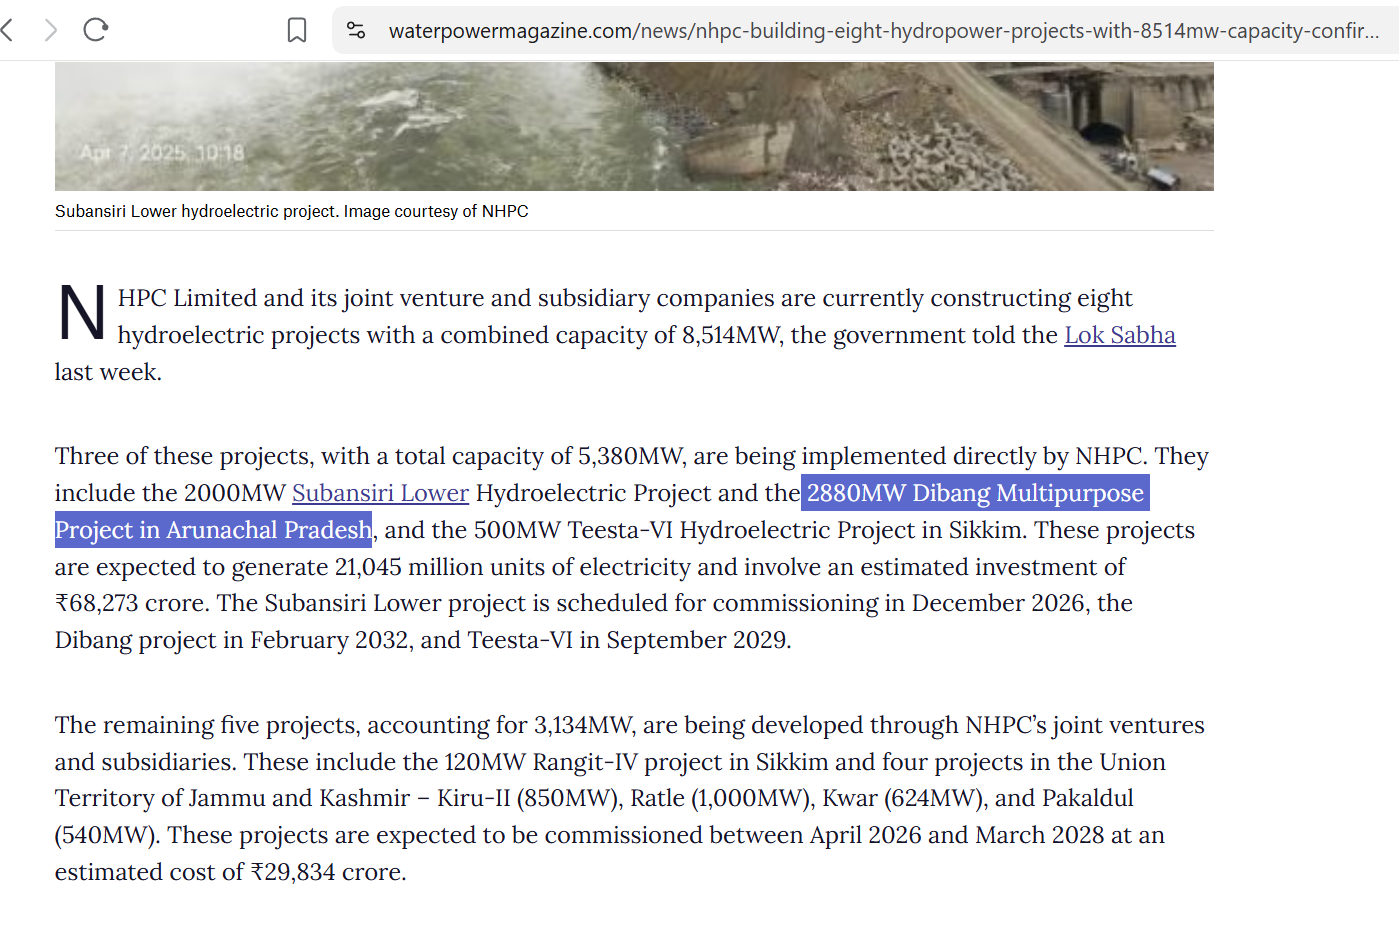

I've uploaded a Progress report by NHPC in the data folder: 
data -> reports_found -> DIBANG MULTIPURPOSE PROJECT (2880 MW), ARUNACHAL PRADESH, PROGRESS REPORT SEPTEMBER 2025.pdf
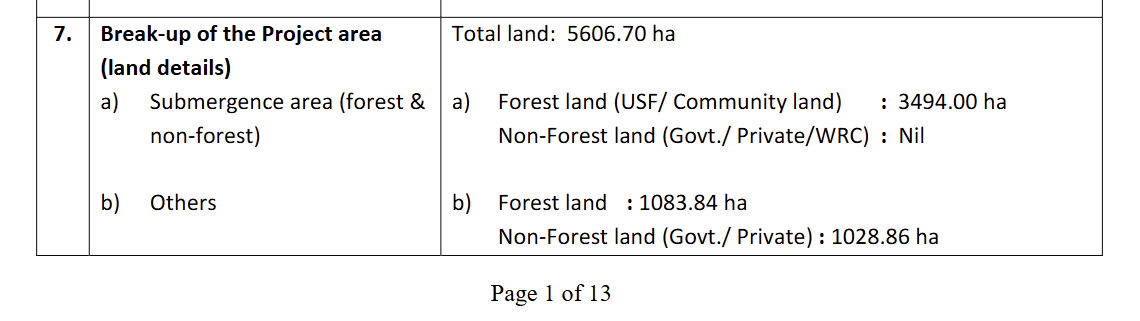

Data Sources: 

After 15th July 2014: https://forestsclearance.nic.in/FCDashboard/FC_Public_Dashboard_Proposals.aspx?Role=Total&State=Arunachal+Pradesh

Before 15th July 2014: https://forestsclearance.nic.in/FCDashboard/FC_Public_Before_2014_Proposals.aspx?Role=Rejected&State=Arunachal%20Pradesh

In [1]:
import pandas as pd

In [2]:
df_after15072014 = pd.read_excel('FC_dashboard_data/Status of FC Proposals before 28th June 2022.xlsx', sheet_name='After 15July2014')
df_before15072014 = pd.read_excel('FC_dashboard_data/Status of FC Proposals before 28th June 2022.xlsx', sheet_name='Before 15July2014')

In [3]:
df_after15072014.info()

<class 'pandas.DataFrame'>
RangeIndex: 211 entries, 0 to 210
Data columns (total 45 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   Year_of_Submission                            211 non-null    int64  
 1   State_Name                                    211 non-null    str    
 2   Proposal_No                                   211 non-null    str    
 3   Proposal_Name                                 211 non-null    str    
 4   User_Agency_Name                              211 non-null    str    
 5   Legal_Status_UserAgency                       211 non-null    str    
 6   File_No                                       105 non-null    str    
 7   Category                                      211 non-null    str    
 8   Shape_of_Forest_Land                          211 non-null    str    
 9   Area_Applied                                  211 non-null    float64
 10  A

In [4]:
div_cols = df_after15072014.filter(regex=r'^Division\d+$').columns
df_after15072014['Division'] = df_after15072014[div_cols].ffill(axis=1).iloc[:, -1]
df_after15072014.drop(['Division1', 'Division2', 'Division3', 'Division4', 'Division5', 'Division6', 'Division7', 'Division8', 'Division9', 'Division10', 'Division11', 'Division12'], axis=1, inplace=True)

dist_cols = df_after15072014.filter(regex=r'^District\d+$').columns
df_after15072014['District'] = df_after15072014[dist_cols].ffill(axis=1).iloc[:, -1]
df_after15072014.drop(['District1', 'District2', 'District3', 'District4', 'District5', 'District6', 'District7', 'District8', 'District9', 'District10', 'District11', 'District12'], axis=1, inplace=True)
df_after15072014.info()

<class 'pandas.DataFrame'>
RangeIndex: 211 entries, 0 to 210
Data columns (total 23 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   Year_of_Submission                            211 non-null    int64  
 1   State_Name                                    211 non-null    str    
 2   Proposal_No                                   211 non-null    str    
 3   Proposal_Name                                 211 non-null    str    
 4   User_Agency_Name                              211 non-null    str    
 5   Legal_Status_UserAgency                       211 non-null    str    
 6   File_No                                       105 non-null    str    
 7   Category                                      211 non-null    str    
 8   Shape_of_Forest_Land                          211 non-null    str    
 9   Area_Applied                                  211 non-null    float64
 10  A

In [5]:
print(df_before15072014.info())

<class 'pandas.DataFrame'>
RangeIndex: 43 entries, 0 to 42
Data columns (total 24 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   Year_of_Submission                            43 non-null     int64  
 1   State_Name                                    43 non-null     str    
 2   Proposal_No                                   43 non-null     str    
 3   Proposal_Name                                 43 non-null     str    
 4   User_Agency_Name                              12 non-null     str    
 5   File_No                                       43 non-null     str    
 6   Category                                      43 non-null     str    
 7   Shape_of_Forest_Land                          3 non-null      str    
 8   Area_Applied                                  43 non-null     float64
 9   Area_Diverted                                 13 non-null     float64
 10  Leg

In [6]:
df_before15072014.drop('Project_Status', axis=1, inplace=True)
df_before15072014.info()

<class 'pandas.DataFrame'>
RangeIndex: 43 entries, 0 to 42
Data columns (total 23 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   Year_of_Submission                            43 non-null     int64  
 1   State_Name                                    43 non-null     str    
 2   Proposal_No                                   43 non-null     str    
 3   Proposal_Name                                 43 non-null     str    
 4   User_Agency_Name                              12 non-null     str    
 5   File_No                                       43 non-null     str    
 6   Category                                      43 non-null     str    
 7   Shape_of_Forest_Land                          3 non-null      str    
 8   Area_Applied                                  43 non-null     float64
 9   Area_Diverted                                 13 non-null     float64
 10  Leg

In [7]:
df = pd.concat([df_before15072014, df_after15072014], ignore_index=True)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 254 entries, 0 to 253
Data columns (total 25 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   Year_of_Submission                            254 non-null    int64  
 1   State_Name                                    254 non-null    str    
 2   Proposal_No                                   254 non-null    str    
 3   Proposal_Name                                 254 non-null    str    
 4   User_Agency_Name                              223 non-null    str    
 5   File_No                                       148 non-null    str    
 6   Category                                      254 non-null    str    
 7   Shape_of_Forest_Land                          214 non-null    str    
 8   Area_Applied                                  254 non-null    float64
 9   Area_Diverted                                 111 non-null    float64
 10  L

In [8]:
fc_approved_or_closed = df[df['Category']=="Hydel"].loc[df['Current_Project_Status'].str.upper().isin(['APPROVED', 'CLOSED']), 'Area_Applied'].sum()
fc_approved_or_closed_ct = df[df['Category']=="Hydel"].loc[df['Current_Project_Status'].str.upper().isin(['APPROVED', 'CLOSED']), 'Area_Applied'].count()
print(f'total forest clearance closed and approved: {fc_approved_or_closed_ct}, {fc_approved_or_closed} hectares')

fc_in_progress = df[df['Category']=="Hydel"].loc[~df['Current_Project_Status'].isin(['APPROVED', 'CLOSED', 'Closed', 'REJECTED', 'Rejected', 'RETURNED', 'Returned', 'REVOKED', 'Withdrawn', 'DELISTED (due to non-reply of EDS by UA within 90 days)']), 'Area_Applied'].sum()
fc_in_progress_ct = df[df['Category']=="Hydel"].loc[~df['Current_Project_Status'].isin(['APPROVED', 'CLOSED', 'Closed', 'REJECTED', 'Rejected', 'RETURNED', 'Returned', 'REVOKED', 'Withdrawn', 'DELISTED (due to non-reply of EDS by UA within 90 days)']), 'Area_Applied'].count()
print(f'total forest clearance in progress: {fc_in_progress_ct}, {fc_in_progress} hectares')

total forest clearance closed and approved: 4, 6460.9400000000005 hectares
total forest clearance in progress: 12, 3738.945 hectares


In [9]:
fc_rejected = df[df['Category']=="Hydel"].loc[df['Current_Project_Status'].isin(['REJECTED', 'Rejected', 'RETURNED', 'Returned', 'REVOKED', 'DELISTED (due to non-reply of EDS by UA within 90 days)']), 'Area_Applied'].sum()
fc_rejected_ct = df[df['Category']=="Hydel"].loc[df['Current_Project_Status'].isin(['REJECTED', 'Rejected', 'RETURNED', 'Returned', 'REVOKED', 'DELISTED (due to non-reply of EDS by UA within 90 days)']), 'Area_Applied'].count()
print(f'total forest clearance rejected: {fc_rejected_ct}, {fc_rejected} hectares')

fc_withdrawn = df[df['Category']=="Hydel"].loc[df['Current_Project_Status'] == 'Withdrawn', 'Area_Applied'].sum()
fc_withdrawn_ct = df[df['Category']=="Hydel"].loc[df['Current_Project_Status']== 'Withdrawn', 'Area_Applied'].count()
print(f'total forest clearance withdrawn: {fc_withdrawn_ct}, {fc_withdrawn} hectares')

total forest clearance rejected: 6, 2164.96 hectares
total forest clearance withdrawn: 2, 40.616 hectares


# Overall status of forest clearance (FC) for hydro power projects, as on June 28th 2022:

In [ ]:
new_df = pd.DataFrame({
    'status': ['Approved or closed', 'In progress', 'Rejected'],
    'count': [fc_approved_or_closed_ct, fc_in_progress_ct,fc_rejected_ct],
    'hectares': [round(fc_approved_or_closed,2), round(fc_in_progress,2), round(fc_rejected, 2)]
})

new_df.head()


,status,count,hectares
0,Approved or closed,4,6460.94
1,In progress,12,3738.94
2,Rejected,6,2164.96


# This is the status of FC for hydro power project proposals submitted BEFORE 15th July 2014:

In [11]:
df_before15072014[df_before15072014['Category']=="Hydel"]['Current_Project_Status'].value_counts()

Current_Project_Status
Rejected    3
REJECTED    2
Closed      2
Returned    1
Name: count, dtype: int64

# This is the status of FC for hydro power project proposals submitted AFTER 15th July 2014:

In [12]:
df_after15072014[df_after15072014['Category']=="Hydel"]['Current_Project_Status'].value_counts()

Current_Project_Status
DFO                7
IN-PRINCIPLE       3
Pending With-SG    2
Withdrawn          2
APPROVED           2
Name: count, dtype: int64

# Below is detailed views of the proposals already approved and in progress:

These are the project proposals where forest clearance have been approved, as on June 28th 2022

In [13]:
df[(df['Category'] == 'Hydel') & (df['Current_Project_Status'].str.upper().isin(['APPROVED', 'CLOSED']))]

,Year_of_Submission,State_Name,Proposal_No,Proposal_Name,User_Agency_Name,File_No,Category,Shape_of_Forest_Land,Area_Applied,Area_Diverted,...,Received_date_ROHO_or_SG_Recommendation_Date,Stage_I_Date,Stage_II_Date,Region_Name,Current_Project_Status,Issuing_Authority,Form_Type,Valid_Status,Division,District
2,2010,Arunachal Pradesh,FP/AR/HYD/9115/2010,"""PROPOSAL FOR DIVERSION OF 6014.18 HA OF FORES...","""JAYPEE ARUNACHAL POWER LTD""","""8-01/2015-FC""",Hydel,NaN,6014.18,6014.18,...,23 Dec 2014,NaN,21 Jan 2016,Guwahati,Closed,HO,Old FC,NaN,NaN,NaN
9,2014,Arunachal Pradesh,FP/AR/HYD/8826/2014,"""PROPOSAL FOR DIVERSION OF 439.68 HA OF FOREST...","""M/s JAYPEE ARUNACHAL POWER Ltd.""","""8-02/2015-FC""",Hydel,NaN,439.68,0.00,...,17 Dec 2014,NaN,02 Dec 2015,Guwahati,Closed,HO,Old FC,NaN,NaN,NaN
53,2020,Arunachal Pradesh,FP/AR/HYD/48835/2020,Ressing HEP (12MW),GEKAM POWER PRIVATE LIMITED,3-AN-B-002-2021-GHY,Hydel,Non Linear,2.33,2.33,...,18 Feb 2021,06 Jul 2023,22 Sep 2023,Guwahati,APPROVED,RO,Form-A (Section 2(ii)): Diversion of Forest Land,VALID,"Sagalee Forest Division, Sagalee",Papum Pare
55,2022,Arunachal Pradesh,FP/AR/HYD/156579/2022,Halaipani Hydro Electric Project (16 MW),HALAIPANI HYDRO PROJECT PRIVATE LIMITED,3-ANB/161/2023/GHY,Hydel,Non Linear,4.75,4.75,...,08 Feb 2023,14 Jan 2025,27 Mar 2026,Guwahati,APPROVED,RO,Form-A (Section 2(ii)): Diversion of Forest Land,VALID,Anjaw Forest Division,Anjaw


These are the project proposals in progress for forest clearance, as on June 28th 2022

In [14]:
df[df['Category']=="Hydel"].loc[~df['Current_Project_Status'].isin(['APPROVED', 'CLOSED', 'Closed', 'REJECTED', 'Rejected', 'RETURNED', 'Returned', 'REVOKED', 'Withdrawn', 'DELISTED (due to non-reply of EDS by UA within 90 days)'])]

,Year_of_Submission,State_Name,Proposal_No,Proposal_Name,User_Agency_Name,File_No,Category,Shape_of_Forest_Land,Area_Applied,Area_Diverted,...,Received_date_ROHO_or_SG_Recommendation_Date,Stage_I_Date,Stage_II_Date,Region_Name,Current_Project_Status,Issuing_Authority,Form_Type,Valid_Status,Division,District
43,2018,Arunachal Pradesh,FP/AR/HYD/33232/2018,DIVERSION OF FOREST LAND OF 10.43 HA (SURFACE ...,YAMMENG GREEN ENERGY PRIVATE LIMITED,3-ANC 097/2017-SHI,Hydel,Non Linear,10.430,10.430,...,17 May 2019,05 Dec 2019,NaN,Guwahati,IN-PRINCIPLE,RO,Form-A (Section 2(ii)): Diversion of Forest Land,VALID,Yingkiong Forest Division,Upper Siang
44,2017,Arunachal Pradesh,FP/AR/HYD/26729/2017,NYIKGONG HYDRO ELECTRIC PROJECT,SRIKAR ENERGY LIMITED,3-ANC 076/2018-SHI,Hydel,Non Linear,11.900,11.900,...,07 May 2019,05 Dec 2019,NaN,Guwahati,IN-PRINCIPLE,RO,Form-A (Section 2(ii)): Diversion of Forest Land,VALID,Yingkiong Forest Division,Upper Siang
45,2017,Arunachal Pradesh,FP/AR/HYD/24848/2017,Rho Hydro Electric Project (93 MW),SEW RHO POWER CORPORATION LTD,NaN,Hydel,Non Linear,48.240,NaN,...,Not Available,NaN,NaN,Guwahati,DFO,NaN,Form-A (Section 2(ii)): Diversion of Forest Land,VALID,Tawang SF Division. Tawang,Tawang
46,2017,Arunachal Pradesh,FP/AR/HYD/26673/2017,CHANGE IN LOCATION OF TWO PATCHES “PH QUARRY S...,HEO HYDRO POWER PRIVATE LIMITED,8-94/2013-FC VOL.,Hydel,Non Linear,4.800,NaN,...,18 Apr 2019,NaN,NaN,Guwahati,DFO,NaN,Form-A (Section 2(ii)): Diversion of Forest Land,VALID,"Aalo Forest Division, Aalo",West Siang
47,2017,Arunachal Pradesh,FP/AR/HYD/24836/2017,Nyukcharong Chu Hydro Electric Project (96 MW),SEW NYUKCHARONG CHU POWER CORPORATION LTD,NaN,Hydel,Non Linear,38.460,NaN,...,Not Available,NaN,NaN,Guwahati,DFO,NaN,Form-A (Section 2(ii)): Diversion of Forest Land,VALID,Tawang SF Division. Tawang,Tawang
48,2017,Arunachal Pradesh,FP/AR/HYD/26244/2017,CHANGE IN LOCATION OF TWO PATCHES “PH QUARRY S...,SIYOTA HYDRO POWER PRIVATE LIMITED,NaN,Hydel,Non Linear,0.800,NaN,...,18 Apr 2019,NaN,NaN,Guwahati,Pending With-SG,NaN,Form-A (Section 2(ii)): Diversion of Forest Land,VALID,"Aalo Forest Division, Aalo",West Siang
49,2017,Arunachal Pradesh,FP/AR/HYD/24816/2017,New Melling Hydro Electric Project (90 MW),SEW NEW MELLING POWER CORPORATION LTD,NaN,Hydel,Non Linear,33.480,NaN,...,Not Available,NaN,NaN,Guwahati,DFO,NaN,Form-A (Section 2(ii)): Diversion of Forest Land,VALID,Tawang SF Division. Tawang,Tawang
50,2019,Arunachal Pradesh,FP/AR/HYD/41630/2019,Papum HEP (15 MW),SONAM HYDRO POWER PRIVATE LIMITED,NaN,Hydel,Non Linear,6.950,NaN,...,17 Aug 2020,NaN,NaN,Guwahati,Pending With-SG,NaN,Form-A (Section 2(ii)): Diversion of Forest Land,VALID,"Banderdewa Forest Division,Banderdewa",Papum Pare
52,2021,Arunachal Pradesh,FP/AR/HYD/143872/2021,Kamala Hydro Electric Power Project (1800MW),KAMALA HYDRO ELECTRIC POWER COMPANY LIMITED,NaN,Hydel,Non Linear,3279.000,NaN,...,Not Available,NaN,NaN,Guwahati,DFO,NaN,Form-A (Section 2(ii)): Diversion of Forest Land,VALID,Kurung Kumey Forest Division,Kra Daadi
54,2022,Arunachal Pradesh,FP/AR/HYD/153202/2022,Dengzi Small Hydro Project(10MW),BAMANG TAGO,3 AN C 168/2023/GHY,Hydel,Linear,6.005,6.005,...,20 Mar 2023,13 Jan 2026,NaN,Guwahati,IN-PRINCIPLE,RO,Form-A (Section 2(ii)): Diversion of Forest Land,VALID,"Shergaon Forest Division,Rupa",West Kameng
